## <font color=blue> Python Lab #10 </font>: Understanding Neural Networks
### *Perceptron* and *Hopfield Networks* 


#### <font color=red> NOTE </font>: 
#1 ipynb file format should be <font color=red> LAB10_yourIDnumber.ipynb </font> ( ex:  LAB10_20245433224234.ipynb ).

#2 If you don't follow the instructions here, there is <font color=red>10 % penalty for each</font>.

#3 Any copied submission won't be graded. 
> 1) i.e., 0 point for every same copy. <br>
> 2) Also, slight modification of one version will be regarded as copy. </font>
>```python
>if copy found:
>    for all copies:
>        score = 0
>```    

----


## single-layer perceptron

In this lab, we will see why a single layer perceptron can simulate Boolean logic—and also why it **can't do XOR**.

---

#### What is a Perceptron?

A **perceptron** is the simplest type of artificial neuron. It takes inputs $x_1, x_2, \dots, x_n$, applies weights $w_1, w_2, \dots, w_n$, adds a bias $b$, and passes the result through a step function:

$$
y = \text{step} \left( \sum_{i=1}^{n} w_i x_i + b \right)
\quad \text{where step}(z) = 
\begin{cases}
1 & \text{if } z \ge 0 \\
0 & \text{otherwise}
\end{cases}
$$

**In the lecture slides**,<font color=red> $b = -T$. </font> (p.19). <br>
It makes a **binary decision** based on whether the weighted input crosses a threshold.

---

#### Linearly Separable Functions

A function is **linearly separable** if you can draw a straight line (in 2D) to separate the inputs into output classes (0 or 1).

#### Examples of linearly separable Boolean functions:

**AND Gate**

| x₁ | x₂ | y |
| -- | -- | - |
| 0  | 0  | 0 |
| 0  | 1  | 0 |
| 1  | 0  | 0 |
| 1  | 1  | 1 |

A line can separate the "1" case from all "0" cases.

**Perceptron weights:**

$$
w_1 = 1,\ w_2 = 1,\ b = -1.5
$$

$$
y = \text{step}(x_1 + x_2 - 1.5)
$$

---

#### XOR Gate: **Not Linearly Separable**

XOR Truth Table

| x₁ | x₂ | y |
| -- | -- | - |
| 0  | 0  | 0 |
| 0  | 1  | 1 |
| 1  | 0  | 1 |
| 1  | 1  | 0 |

There’s **no straight line** that can separate the 1s from the 0s in 2D space. The "1" cases are diagonally opposite, so a single perceptron fails.

This is why **XOR requires at least one hidden layer**—i.e., a **multi-layer perceptron (MLP)** with nonlinear activations.

---



### **Hopfield Networks**
Let’s walk through each step of a Hopfield network with its mathematical formulation, using a 3x3 binary pattern (flattened to a vector of size 9). 

---

### Step 1: Pattern Representation

We represent a 2D pattern as a 1D vector of size $N = 9$ using bipolar values:

**NOTE**: In the lecture slides, we used binary valued neuron, so the later equation for weight is **somewhat different** but both are essentially the same.


$$
\mathbf{x} = \begin{bmatrix}
x_1 & x_2 & \dots & x_9
\end{bmatrix}^\top, \quad x_i \in \{-1, +1\}
$$

---

### Step 2: Weight Matrix (Training with Hebbian Rule)

The Hopfield network is trained using the **Hebbian learning rule**:<br>

$$
W_{ij} = \begin{cases}
x_i x_j & \text{if } i \ne j \\
0 & \text{if } i = j
\end{cases}
$$

This means:

$$
\mathbf{W} = \mathbf{x} \mathbf{x}^\top - N \cdot I
$$

Where:

* $\mathbf{W} \in \mathbb{R}^{9 \times 9}$ is the symmetric weight matrix
* Diagonal elements are set to 0 to avoid self-feedback

---

### Step 3: State Update Rule (Asynchronous)

The state update rule for neuron $i$ is:

$$
s_i^{\text{new}} = \text{sign} \left( \sum_{j=1}^{N} W_{ij} \cdot s_j^{\text{old}} \right)
$$

Or more compactly:

$$
\mathbf{s}^{\text{new}} = \text{sign}( \mathbf{W} \cdot \mathbf{s}^{\text{old}} )
$$

In **asynchronous mode**, <font color=red> you update one neuron at a time using the above formula.</font>

* The sign function is:

  $$
  \text{sign}(x) = \begin{cases}
  +1 & \text{if } x \geq 0 \\
  -1 & \text{if } x < 0
  \end{cases}
  $$

---

### Step 4: Energy Function

Hopfield networks minimize an energy function:

$$
E(\mathbf{s}) = -\frac{1}{2} \sum_{i,j} W_{ij} s_i s_j
$$

Or:

$$
E(\mathbf{s}) = -\frac{1}{2} \mathbf{s}^\top \mathbf{W} \mathbf{s}
$$

Each update reduces or maintains the energy, leading the network toward a stable state (a local minimum of energy).

---

#### More on weight matrix 

In a **Hopfield network**, the **weight matrix** is effectively an **adjacency matrix** of a **fully connected, undirected graph**, with a few key properties tailored for neural computation.

An **adjacency matrix** in graph theory shows which nodes (neurons) are connected, and with what strength. In the Hopfield network:

* The matrix is:

  $$
  W = \begin{bmatrix}
  0 & w_{01} & w_{02} & \dots \\
  w_{10} & 0 & w_{12} & \dots \\
  \vdots & \vdots & \ddots & \vdots
  \end{bmatrix}
  $$
* Each entry $w_{ij}$ represents the **synaptic weight** from neuron $j$ to neuron $i$.
* Since the connections are **symmetric**:

  $$
  w_{ij} = w_{ji}
  $$
* And the diagonal is **zero** (no self-connections):

  $$
  w_{ii} = 0
  $$

So, it’s essentially a **weighted adjacency matrix** for a **fully connected symmetric graph**, where:

* Nodes = neurons
* Edges = synaptic weights

---

#### Neural Interpretation

| Graph Concept       | Hopfield Equivalent         |
| ------------------- | --------------------------- |
| Node                | Neuron                      |
| Edge                | Synapse (connection)        |
| Weight on edge      | Synaptic strength (learned) |
| Symmetric adjacency | Bidirectional communication |

---


#### Example of showing bipolar pattern using `imshow()`(for visualization)
Of course, you can change the set of color or size of figure.

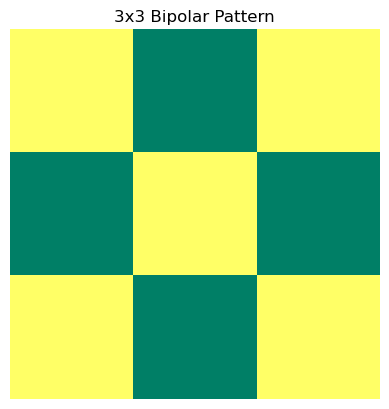

In [106]:
import numpy as np
import matplotlib.pyplot as plt

# Define a 3x3 bipolar pattern
pattern = np.array([
    [ 1, -1,  1],
    [-1,  1, -1],
    [ 1, -1,  1]
])

# Display the pattern using imshow
plt.imshow(pattern, cmap='summer', vmin=-1, vmax=1) 
plt.title("3x3 Bipolar Pattern")
plt.axis('off')  # Turn off axis ticks/labels
plt.show()


#### (1) Write a code to simulate the following 2-input Boolean operations with a single layer perceptron.
You need to test the following gates:
* AND
* OR
* NAND
* NOR
  
For each gate test, draw the corresponding **truth table**.

In [1]:
import numpy as np
from sklearn.neural_network import MLPClassifier

gates = {
    "AND": {
        "inputs": np.array([[0, 0], [0, 1], [1, 0], [1, 1]]),
        "outputs": np.array([0, 0, 0, 1]) 
    },
    "OR": {
        "inputs": np.array([[0, 0], [0, 1], [1, 0], [1, 1]]),
        "outputs": np.array([0, 1, 1, 1]) 
    },
    "NAND": {
        "inputs": np.array([[0, 0], [0, 1], [1, 0], [1, 1]]),
        "outputs": np.array([1, 1, 1, 0])
    },
    "NOR": {
        "inputs": np.array([[0, 0], [0, 1], [1, 0], [1, 1]]),
        "outputs": np.array([1, 0, 0, 0])  
    }
}

for gate, data in gates.items():
    print(f"\nTraining Perceptron for {gate} Gate:")
    clf = MLPClassifier(hidden_layer_sizes=(), activation='identity', solver='lbfgs', max_iter=1000)
    clf.fit(data["inputs"], data["outputs"])

    predictions = clf.predict(data["inputs"])

    print("Input (A, B) -> Output (Y)")
    for i, (inputs, output) in enumerate(zip(data["inputs"], predictions)):
        print(f"{inputs} -> {output}")


Training Perceptron for AND Gate:
Input (A, B) -> Output (Y)
[0 0] -> 0
[0 1] -> 0
[1 0] -> 0
[1 1] -> 1

Training Perceptron for OR Gate:
Input (A, B) -> Output (Y)
[0 0] -> 0
[0 1] -> 1
[1 0] -> 1
[1 1] -> 1

Training Perceptron for NAND Gate:
Input (A, B) -> Output (Y)
[0 0] -> 1
[0 1] -> 1
[1 0] -> 1
[1 1] -> 0

Training Perceptron for NOR Gate:
Input (A, B) -> Output (Y)
[0 0] -> 1
[0 1] -> 0
[1 0] -> 0
[1 1] -> 0


#### (2) Write a code which utilizes Multi-Layer Perceptron (MLP) to solve the XOR problem.
Show the truth table too.

In [3]:
import numpy as np
from sklearn.neural_network import MLPClassifier

inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
outputs = np.array([0, 1, 1, 0]) 

clf = MLPClassifier(hidden_layer_sizes=(2,), activation='relu', solver='lbfgs', max_iter=10000)

clf.fit(inputs, outputs)

predictions = clf.predict(inputs)

print("Input (A, B) -> Output (A XOR B)")
for i, (input_pair, output) in enumerate(zip(inputs, predictions)):
    print(f"{input_pair} -> {output}")

Input (A, B) -> Output (A XOR B)
[0 0] -> 1
[0 1] -> 1
[1 0] -> 1
[1 1] -> 0


#### (3) Write a code to build Hopfield Networks to store and recall memory. 

**Steps**:
1. The memory to store(3x3 bipolar pattern):

``` python
     [[1, -1, -1,
      -1, 1, -1,
      -1, -1, 1]]
```
2. You need to initialize the weight matrix. We can use an adjacency matrix to represent the weight. 

3. Your incomplete input is:

``` python
    [[ 1, -1,  1],
     [-1, -1, -1],
     [ 1,  1,  1]]
```   

4. Update the network asynchronously (meaning: randomly choose a neuron).

5. Whenever you update each neuron, calculate the energy of the network.

6. Visualize each state (i.e., the value of each neuron) update using `imshow()`.

7. Plot the network states and the energy trend. 

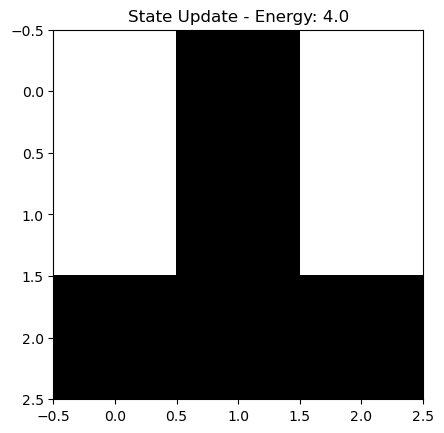

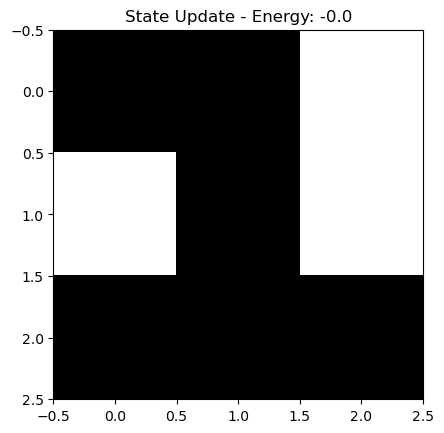

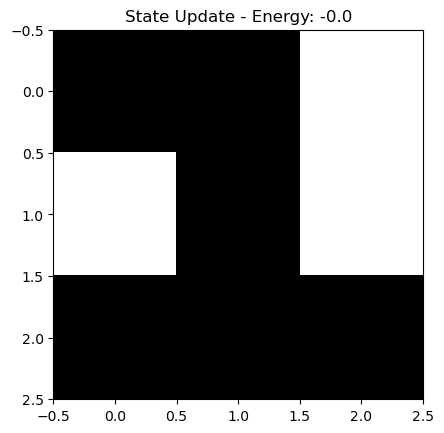

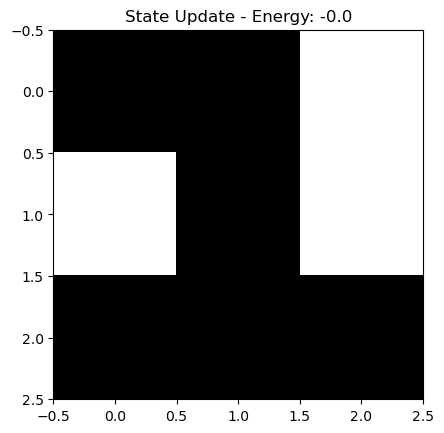

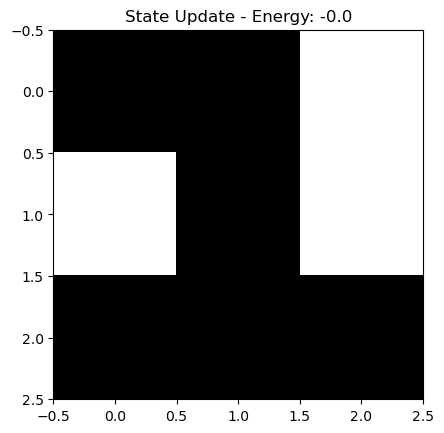

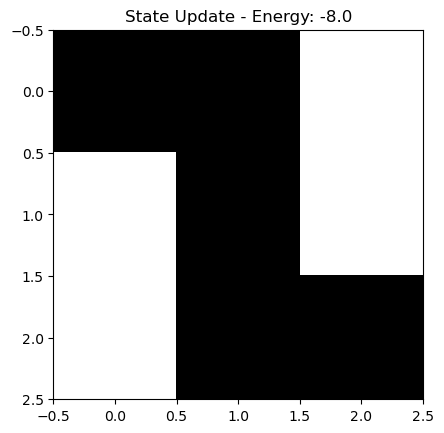

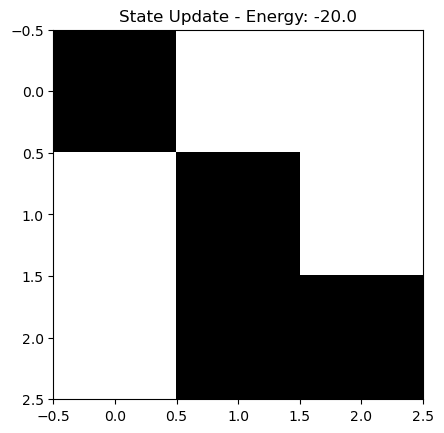

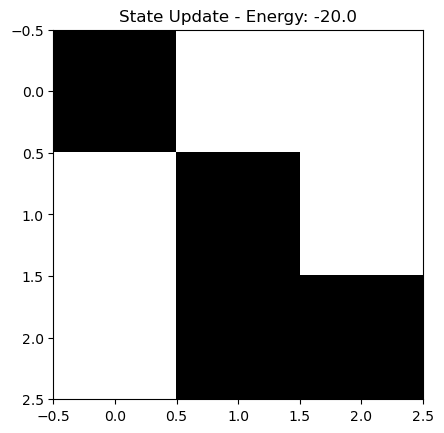

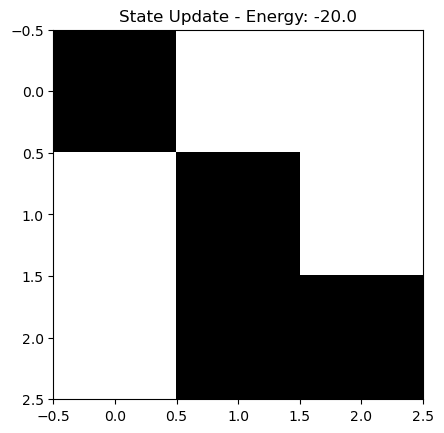

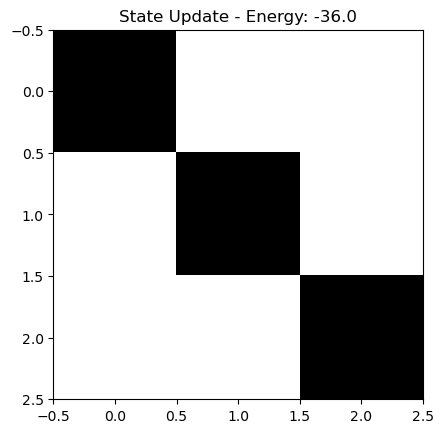

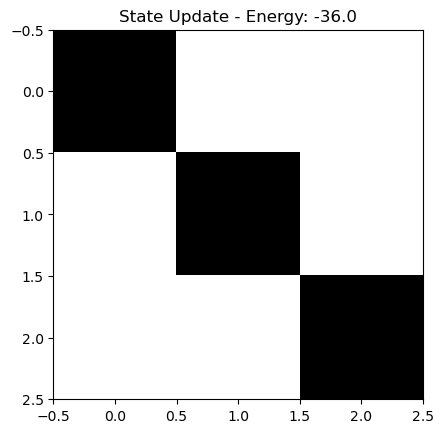

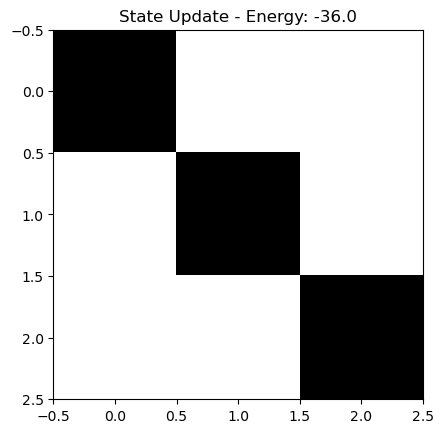

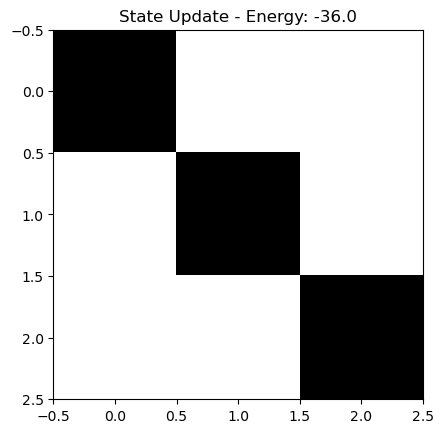

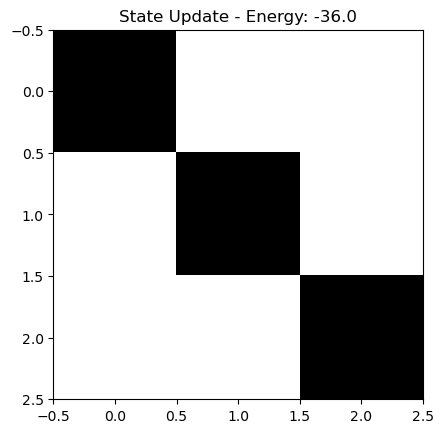

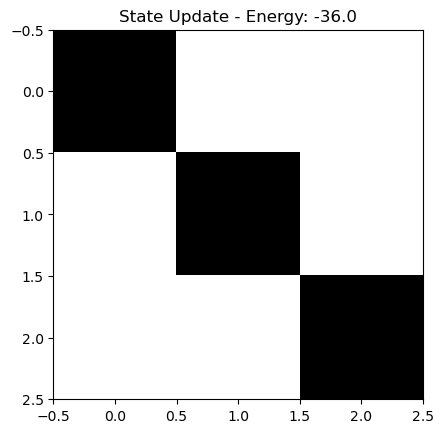

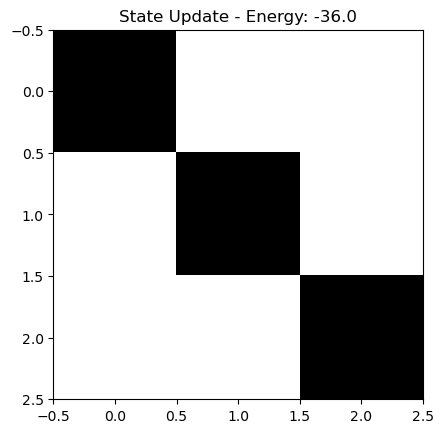

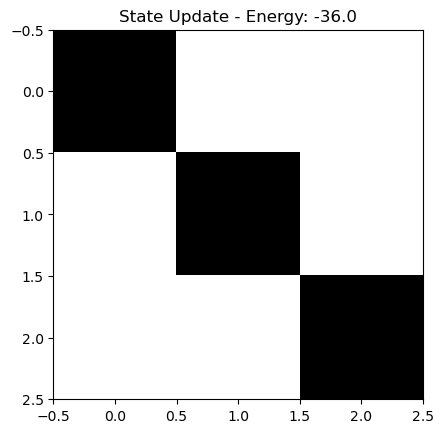

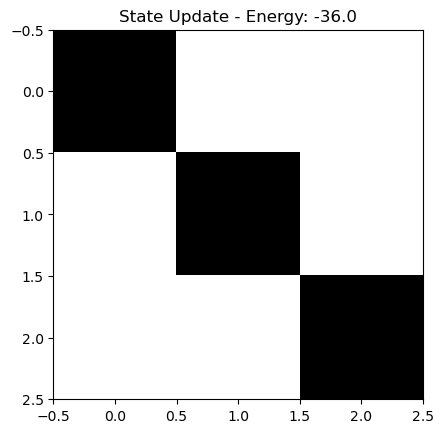

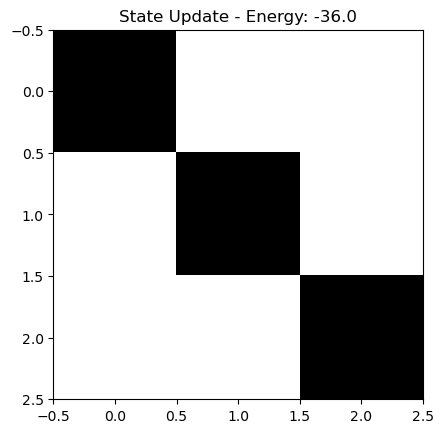

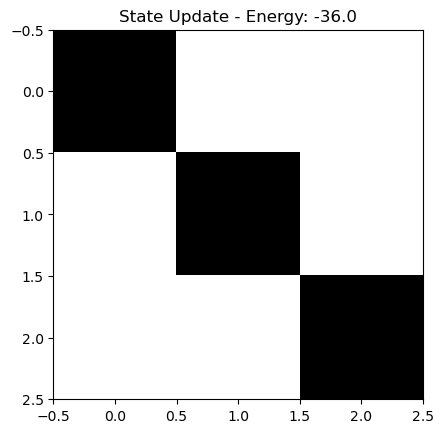

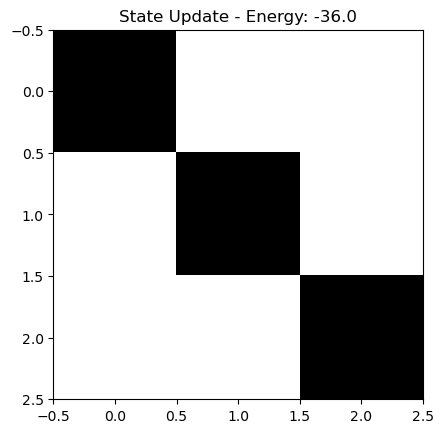

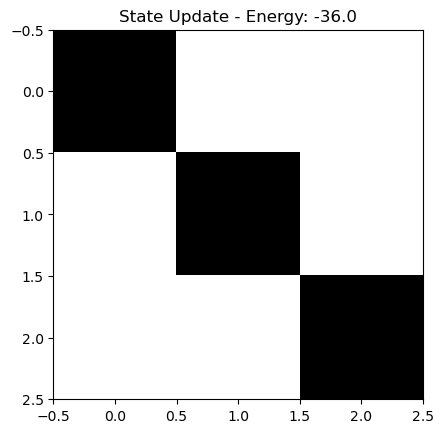

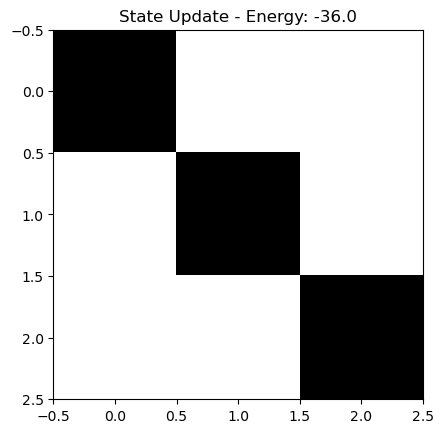

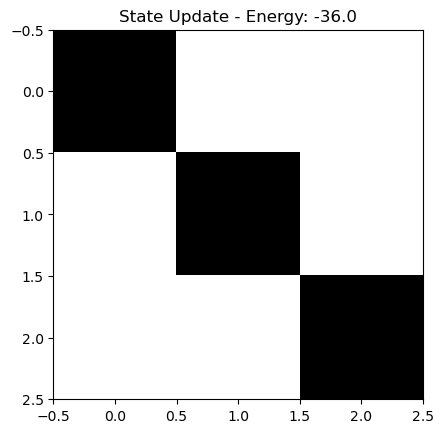

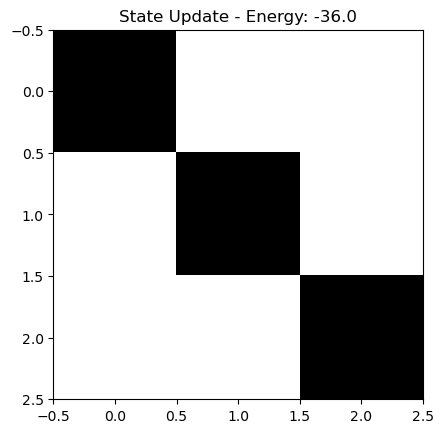

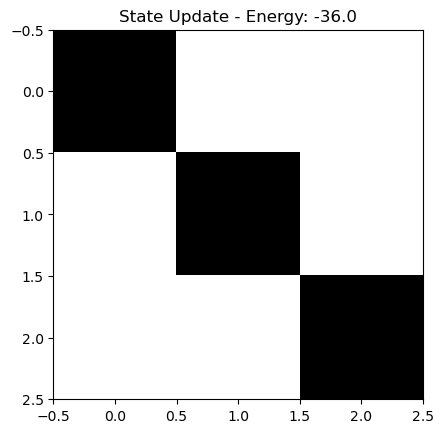

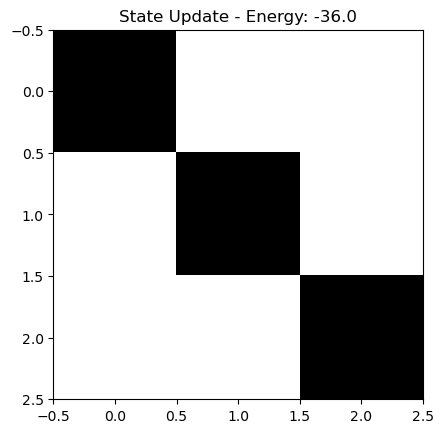

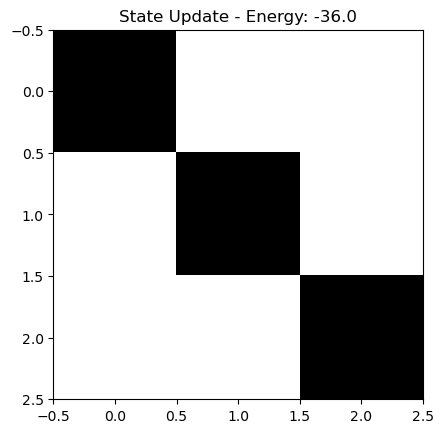

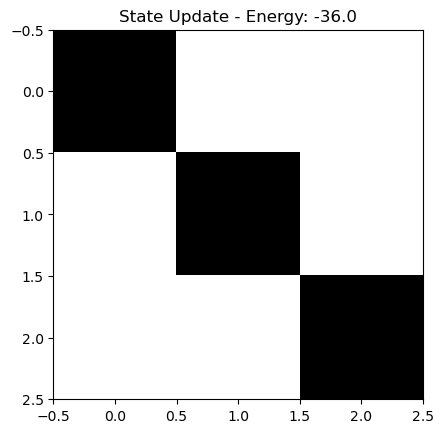

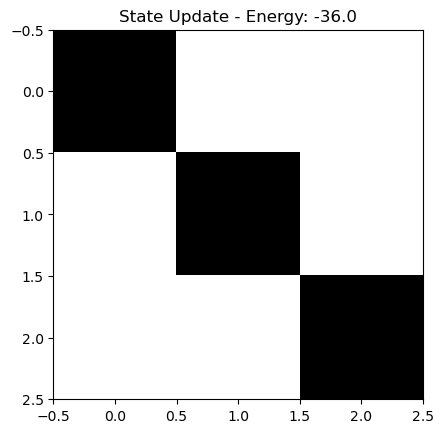

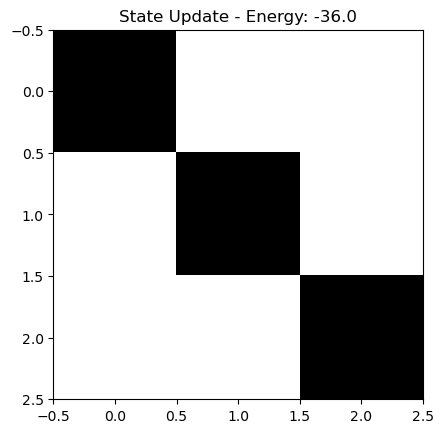

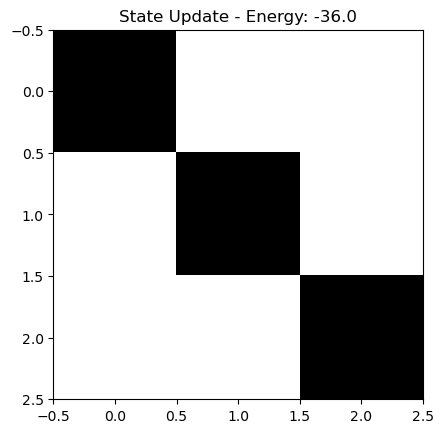

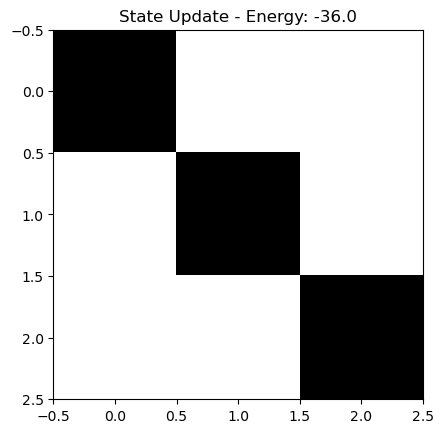

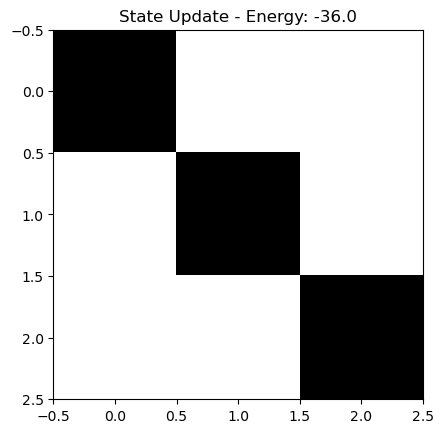

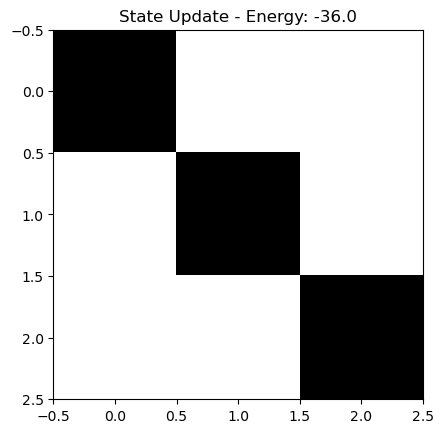

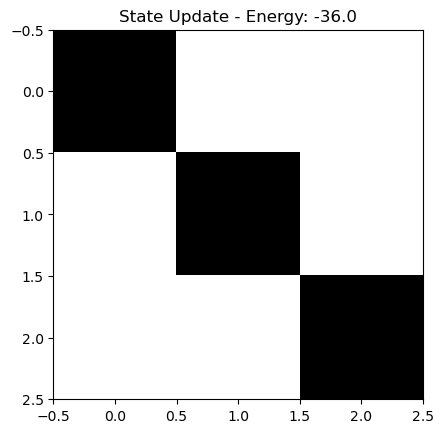

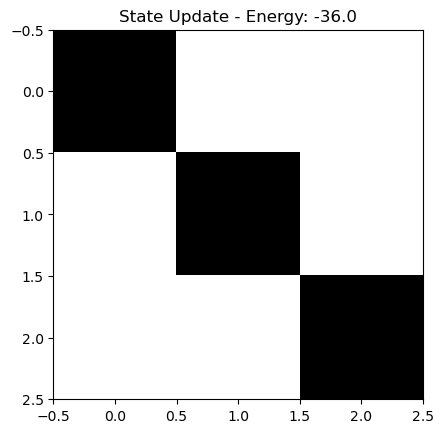

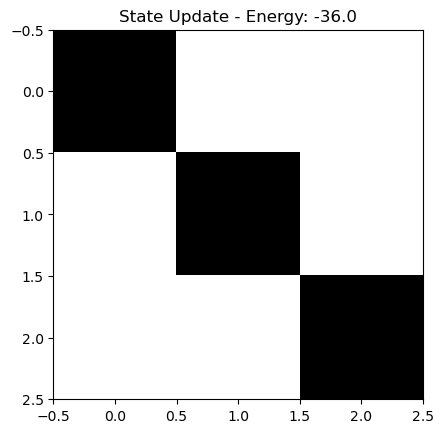

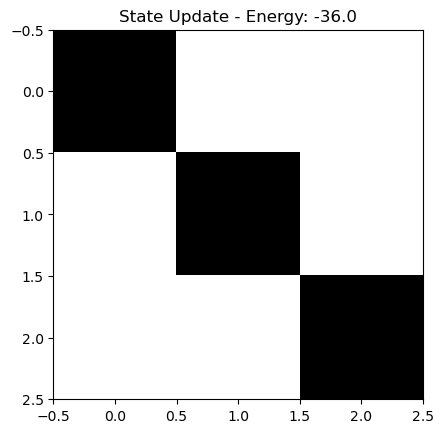

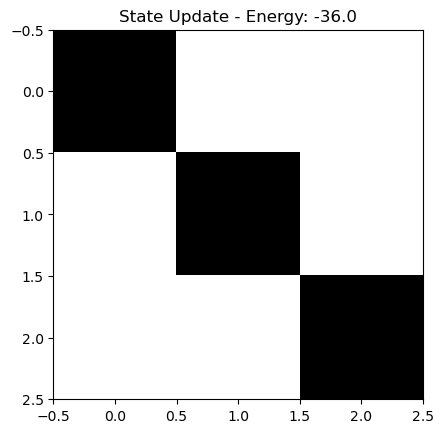

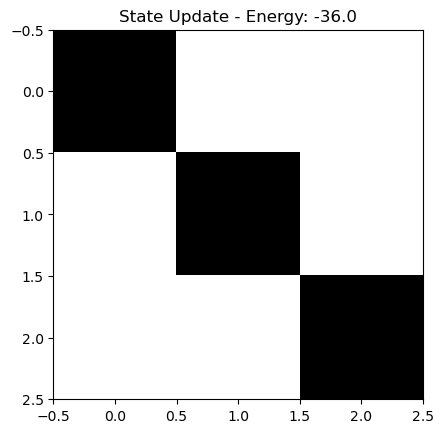

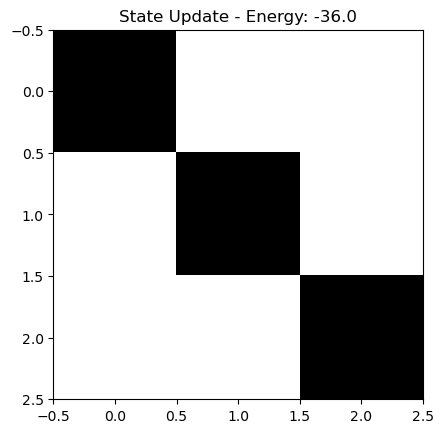

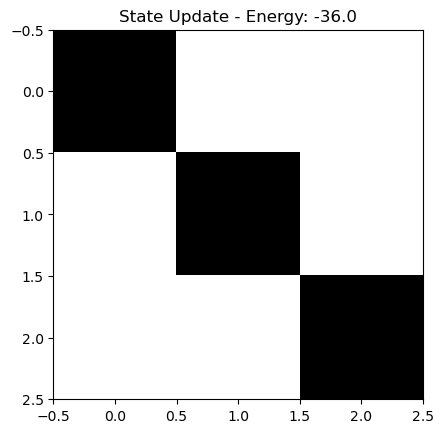

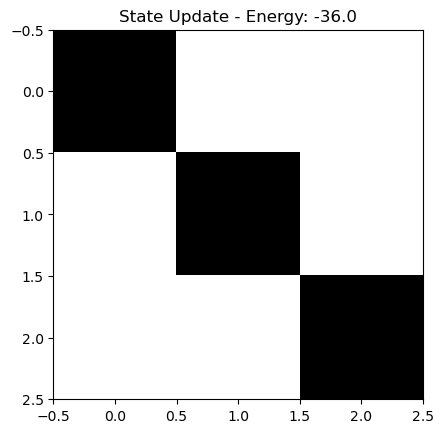

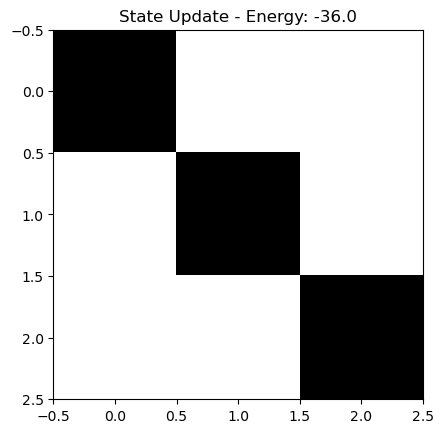

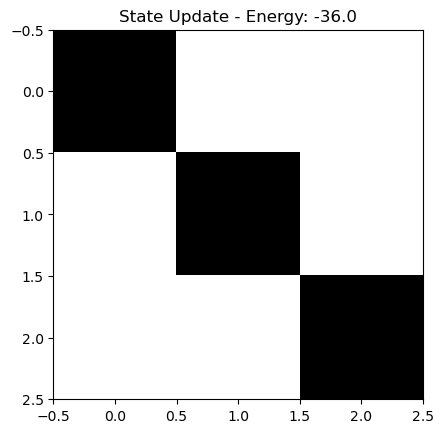

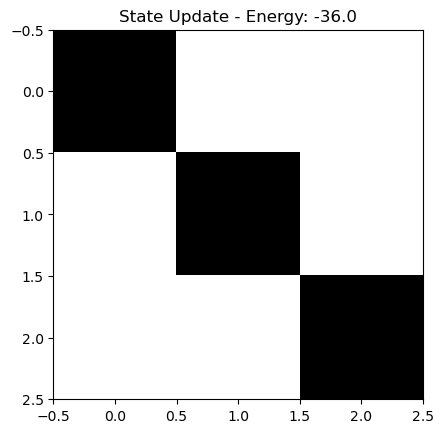

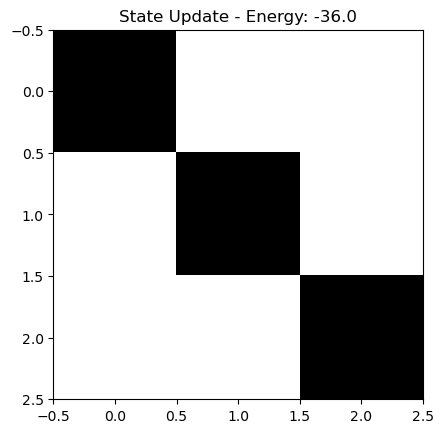

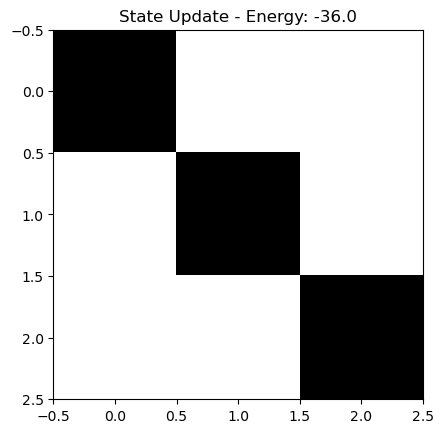

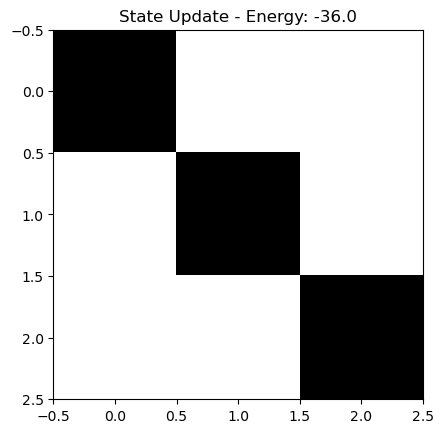

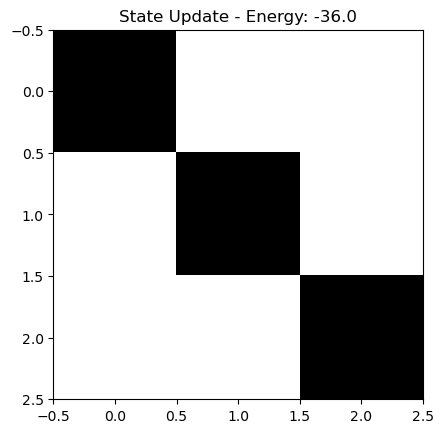

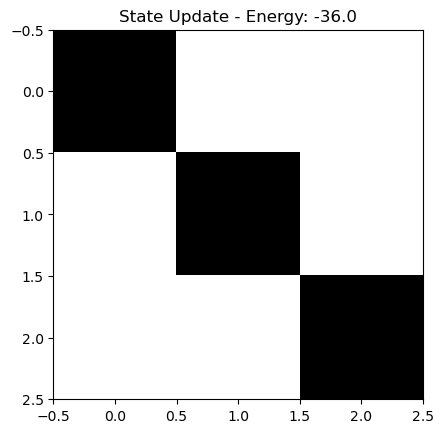

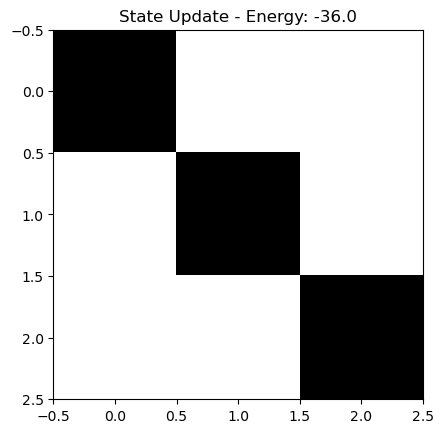

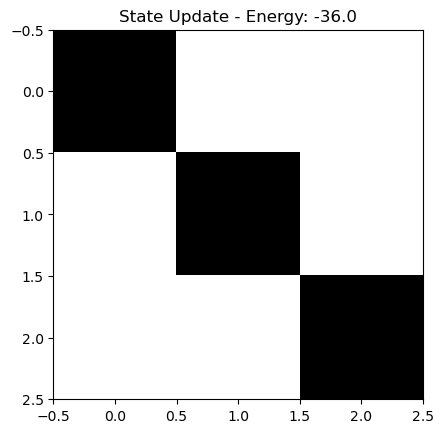

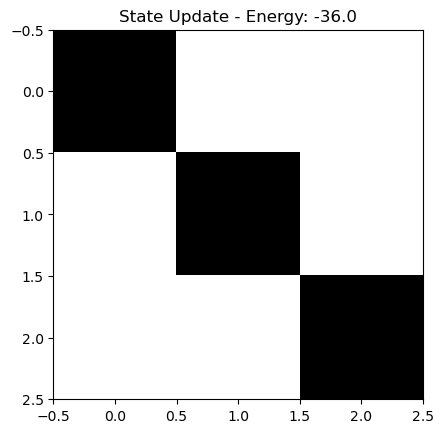

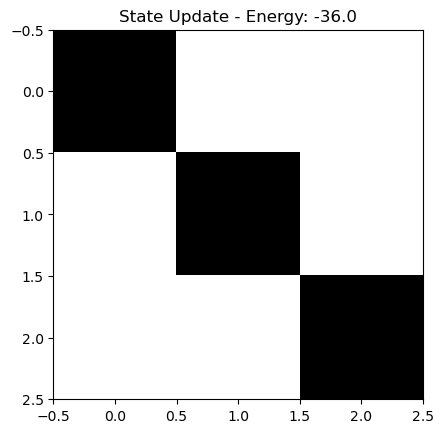

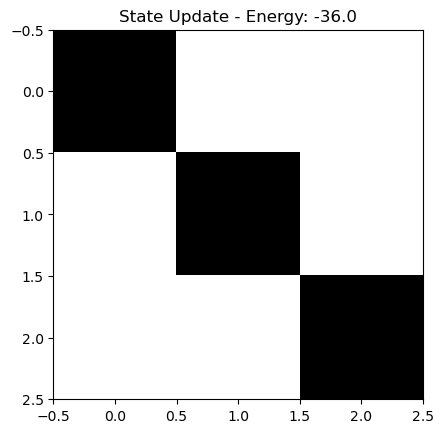

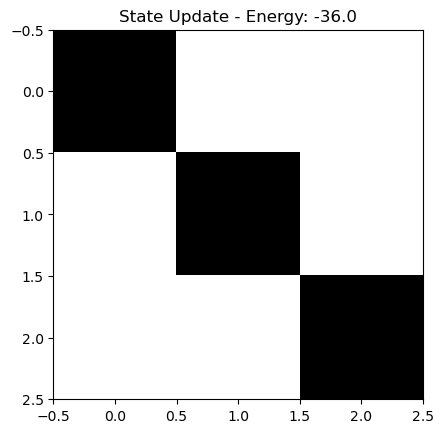

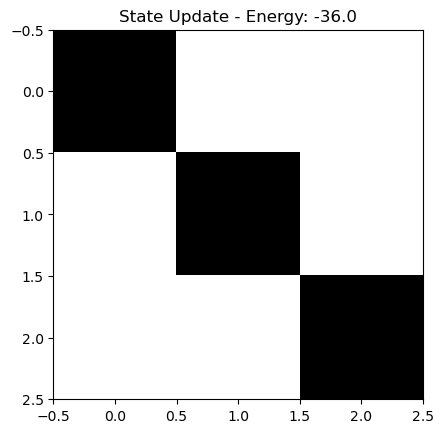

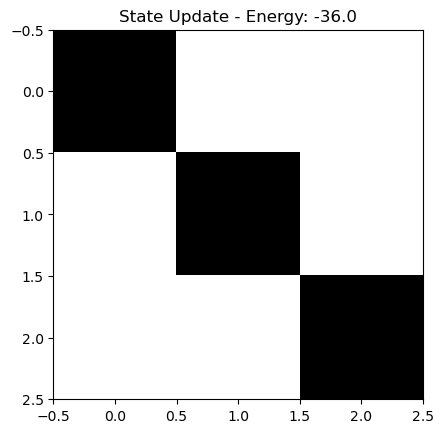

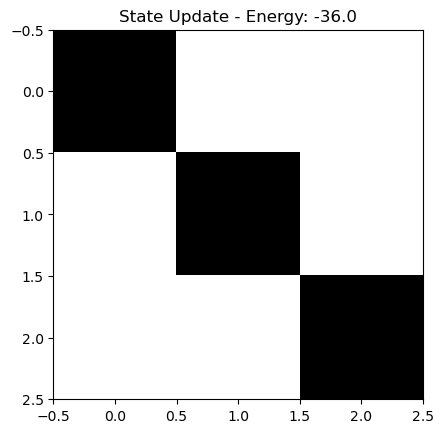

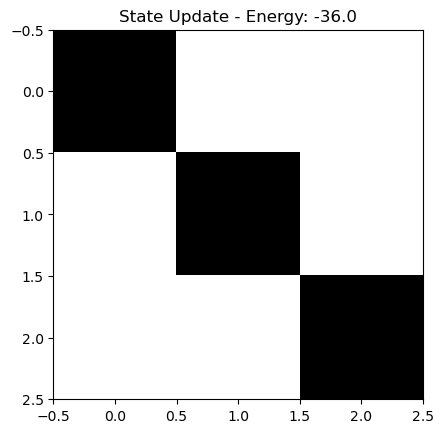

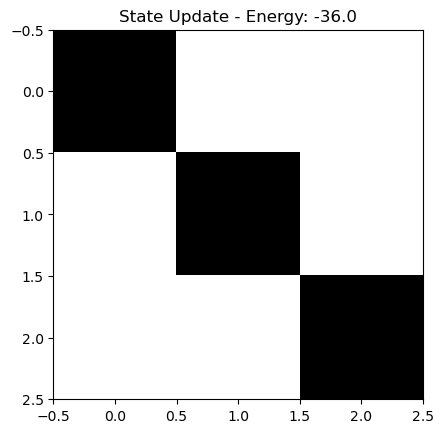

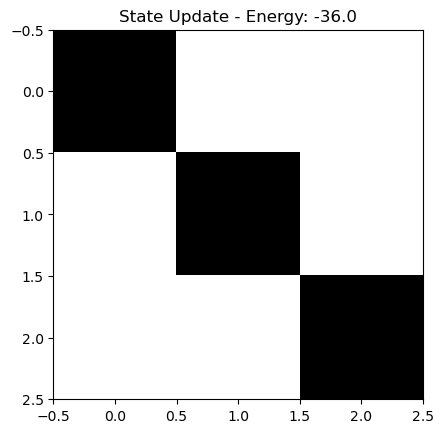

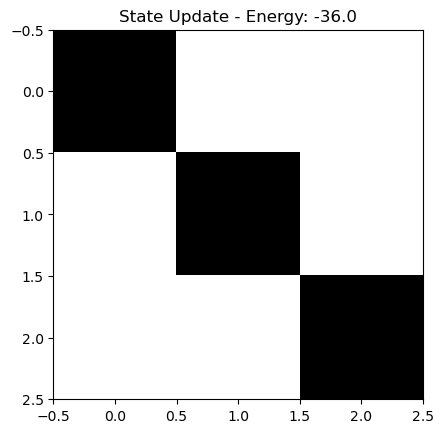

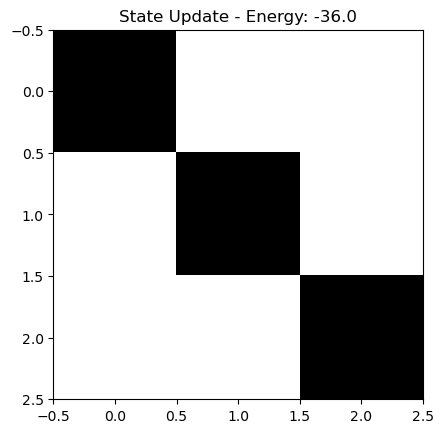

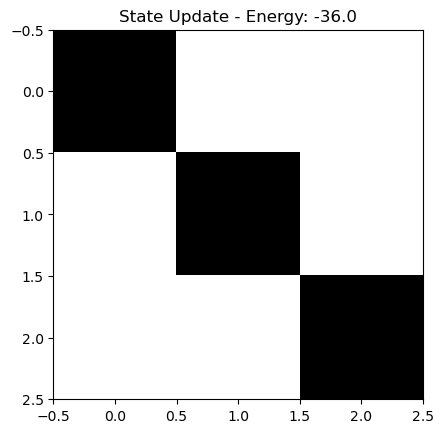

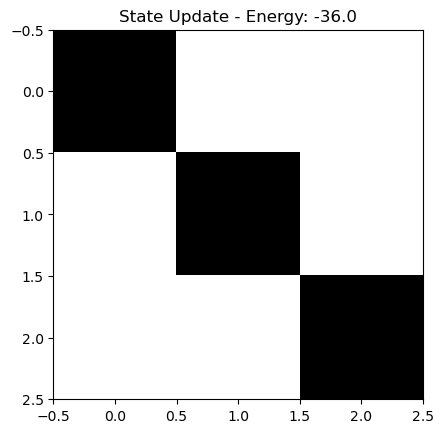

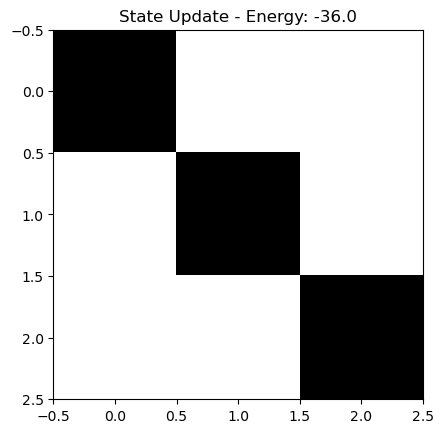

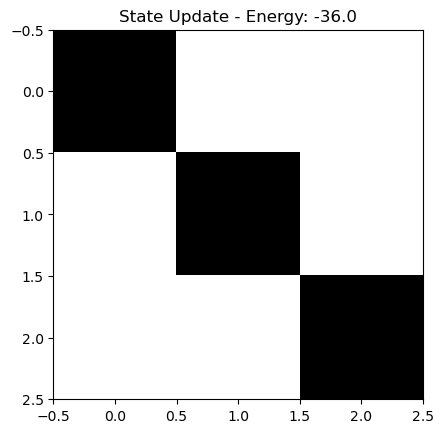

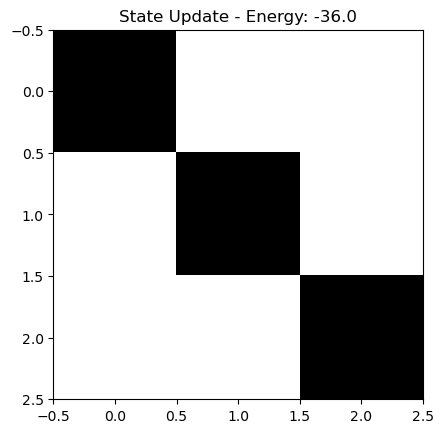

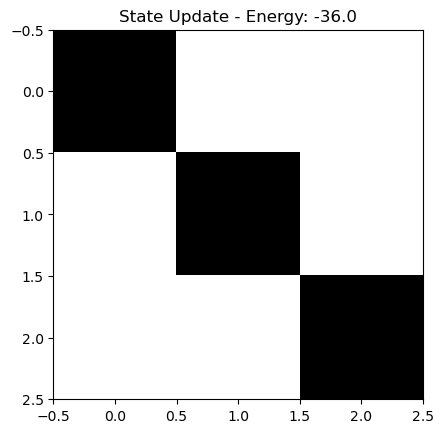

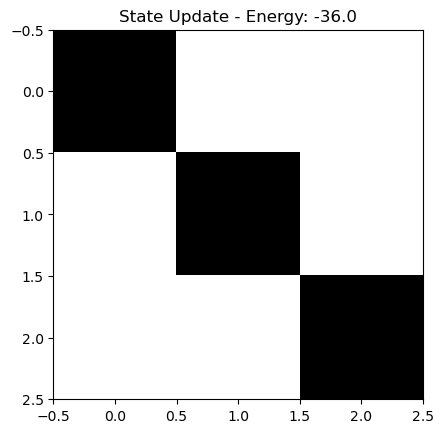

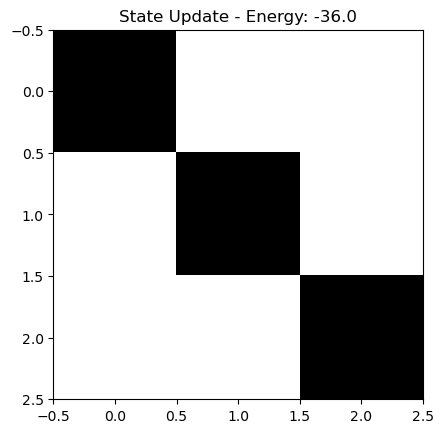

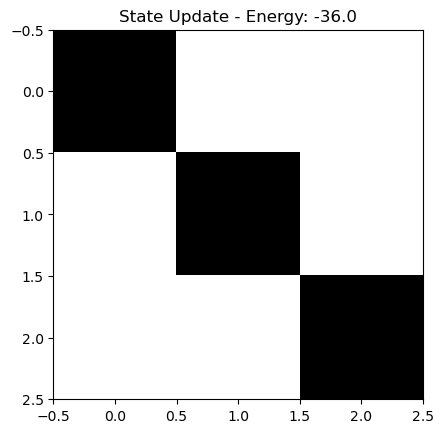

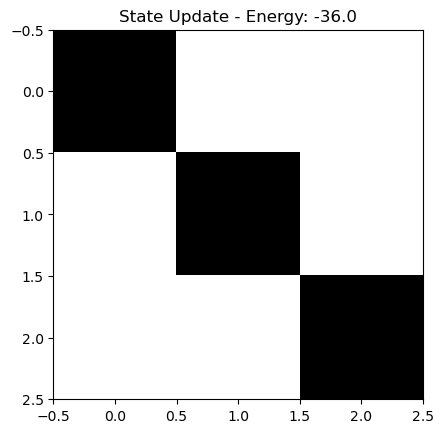

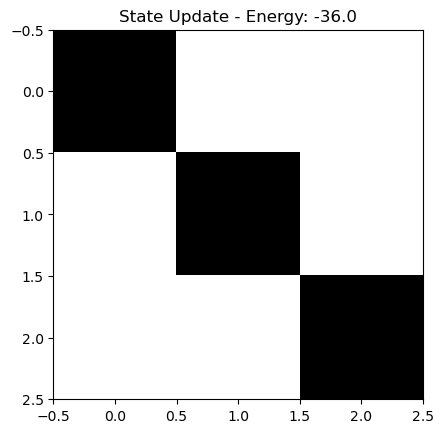

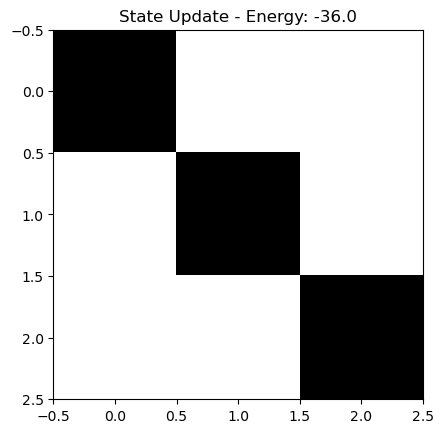

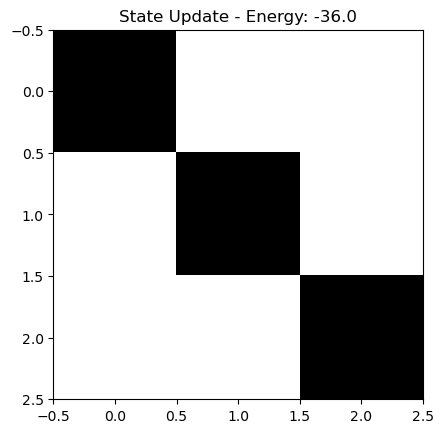

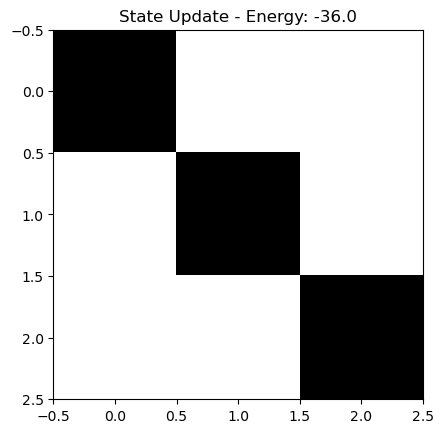

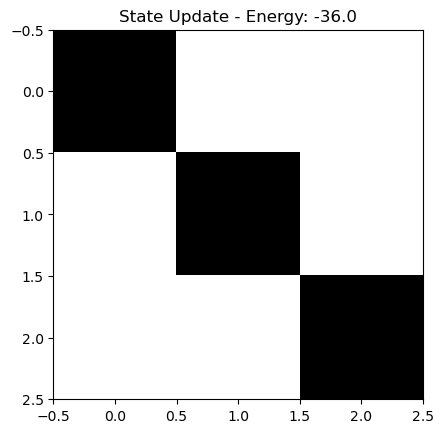

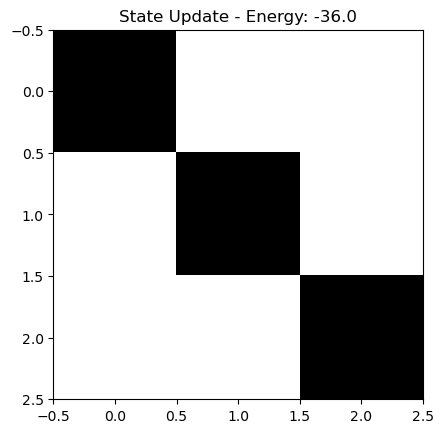

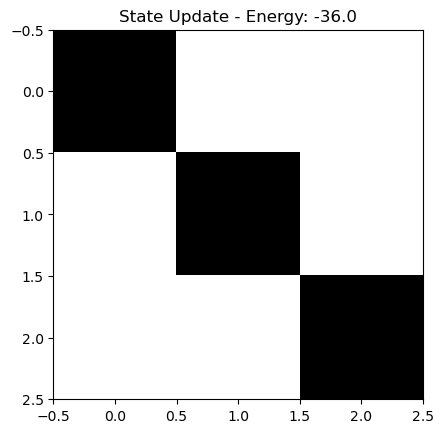

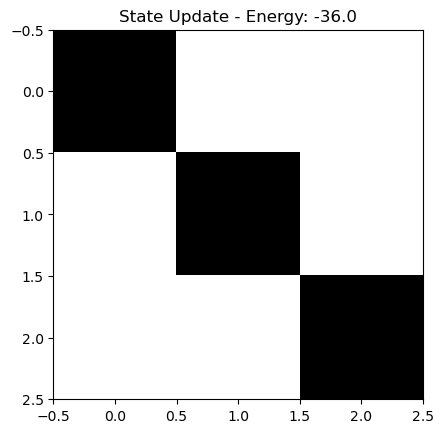

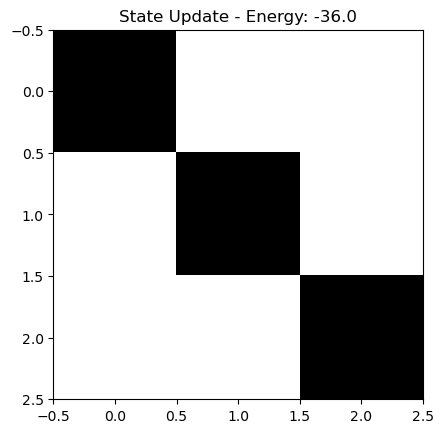

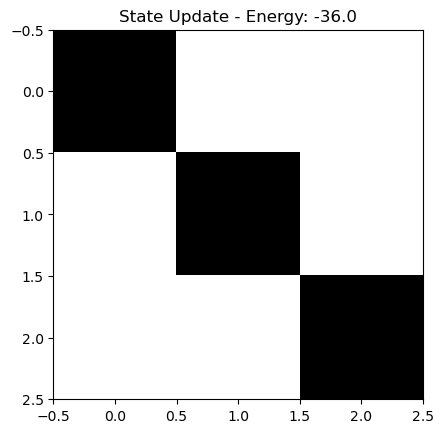

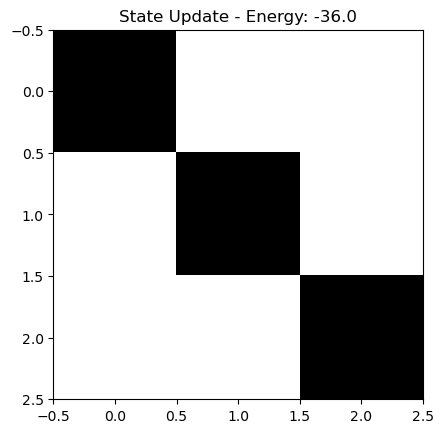

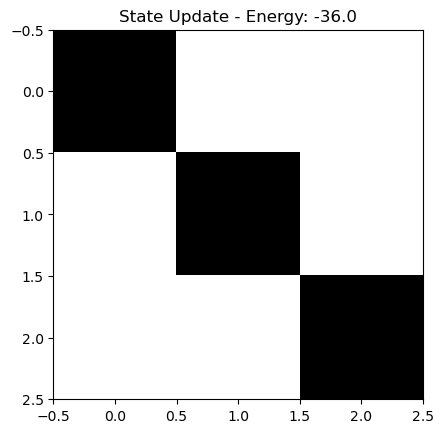

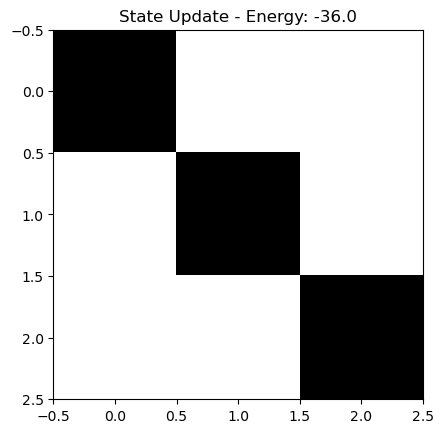

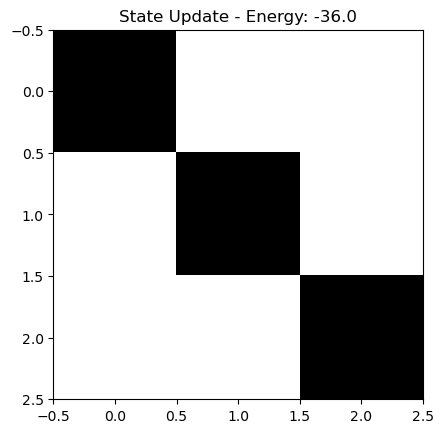

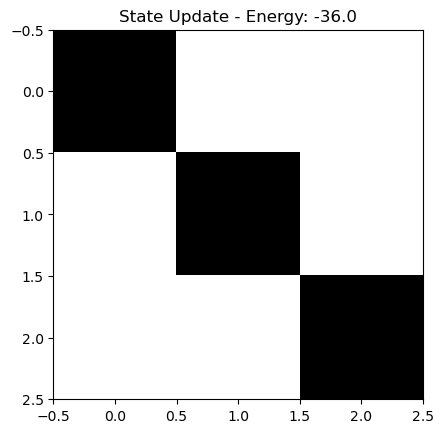

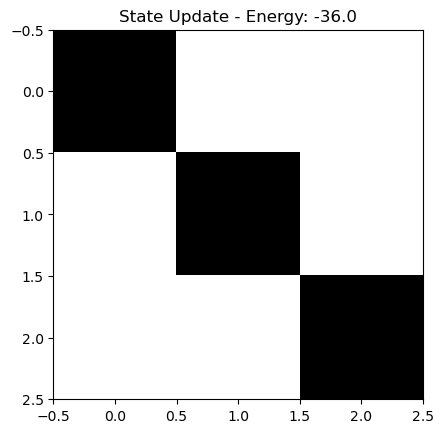

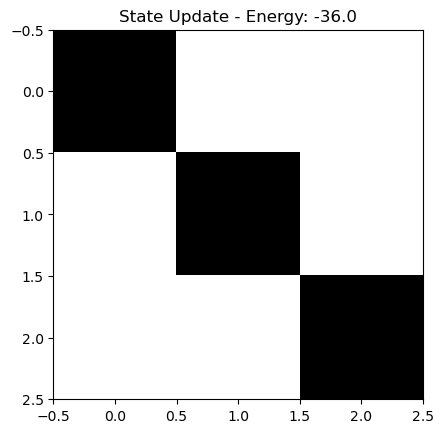

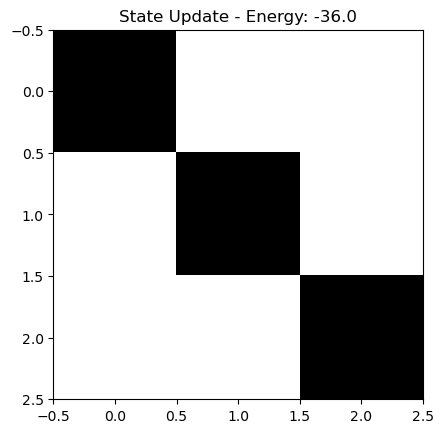

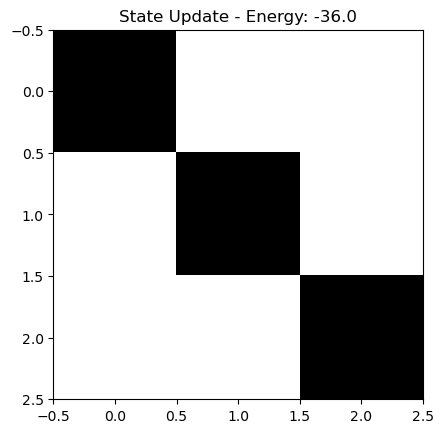

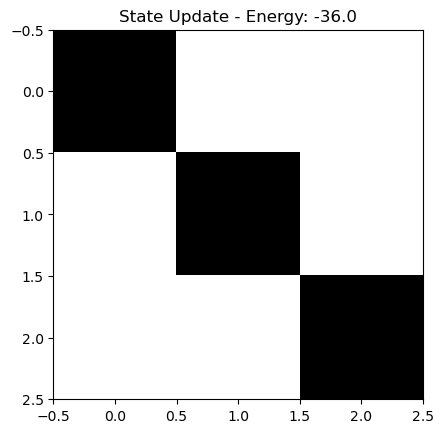

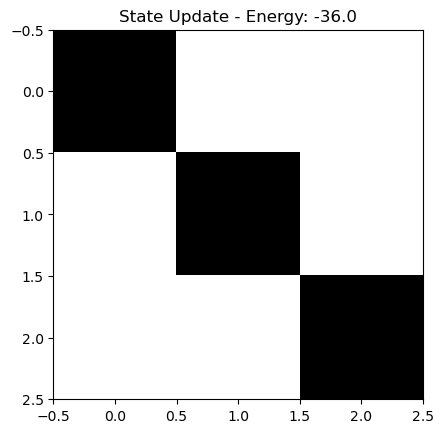

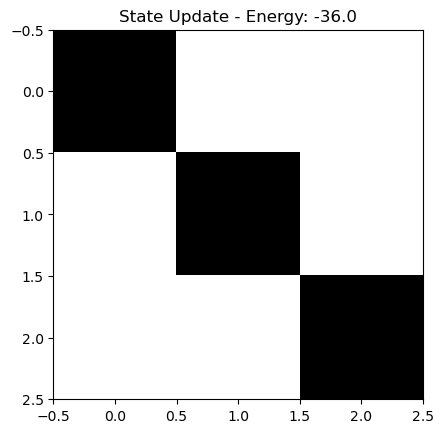

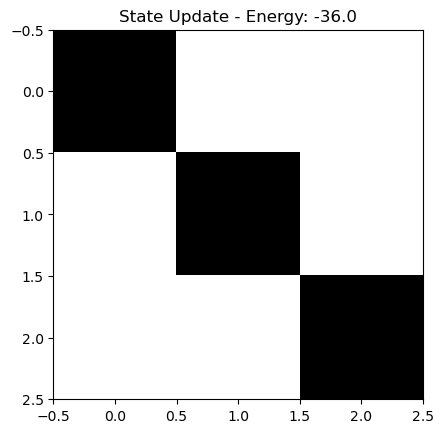

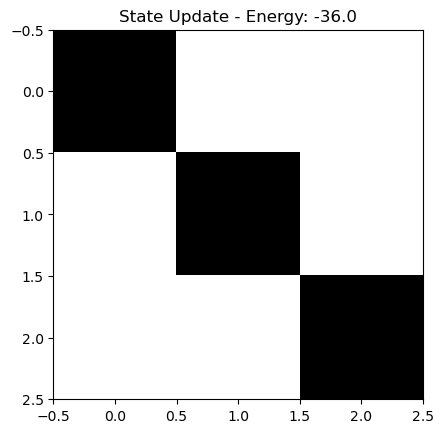

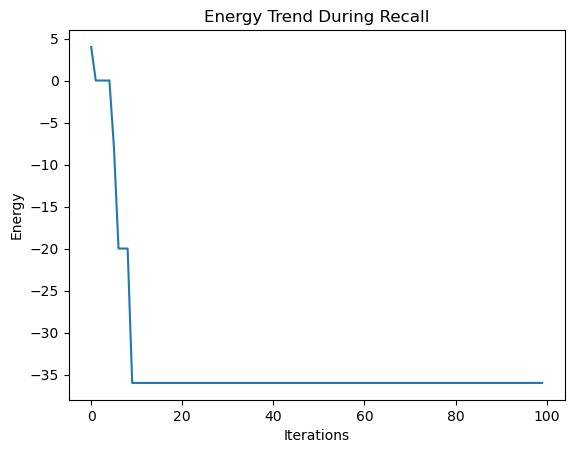

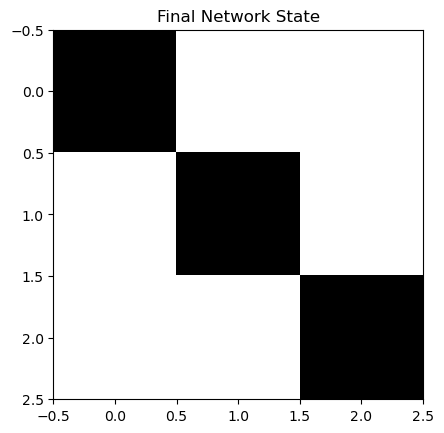

In [5]:
import numpy as np
import matplotlib.pyplot as plt

memory = np.array([[1, -1, -1],
                   [-1, 1, -1],
                   [-1, -1, 1]])

memory_flat = memory.flatten()

def hebbian_learning(patterns):
    N = patterns.shape[1]
    W = np.zeros((N, N))
    for p in patterns:
        W += np.outer(p, p) 
    np.fill_diagonal(W, 0) 
    return W

def update_neuron(W, state, index):
  
    input_sum = np.dot(W[index, :], state)
 
    return 1 if input_sum >= 0 else -1

def calculate_energy(W, state):
    return -0.5 * np.sum(np.dot(state, W) * state)

def hopfield_recall(W, initial_state, max_iterations=100, visualize=True):
    state = initial_state.copy()
    energy_list = []
    states_list = []
    
    for _ in range(max_iterations):
       
        index = np.random.randint(len(state))
     
        state[index] = update_neuron(W, state, index)
      
        energy = calculate_energy(W, state)
        energy_list.append(energy)
        states_list.append(state.copy())
        
        if visualize:
            plt.imshow(state.reshape(3, 3), cmap='binary')
            plt.title(f"State Update - Energy: {energy}")
            plt.pause(0.1) 
    
    return np.array(states_list), np.array(energy_list)

patterns = np.array([memory_flat]) 
W = hebbian_learning(patterns)

initial_state = np.random.choice([-1, 1], size=memory_flat.shape)

states, energy = hopfield_recall(W, initial_state, max_iterations=100)

plt.figure()
plt.plot(energy)
plt.title('Energy Trend During Recall')
plt.xlabel('Iterations')
plt.ylabel('Energy')
plt.show()

plt.figure()
plt.imshow(states[-1].reshape(3, 3), cmap='binary')
plt.title('Final Network State')
plt.show()